# 2025년 한식 조리 재료 데이터셋

2025년 파일의 **전체 SKU**를 공개 레시피·식재료 자료에 연결해 선별합니다.
채소·버섯·생고기·달걀·기본 양념과 두부·어묵·떡국떡 같은 조리 재료를 포함하고,
완제품·반찬·밀키트·간식은 제외합니다. 이는 상품명 규칙을 통과한 **재료 후보**이며,
실제 한식 소비나 개별 상품의 공식 분류를 뜻하지 않습니다.

커널: **Python (hit-stocks-analysis)** → Restart Kernel and Run All Cells.
실행하면 `data/hansik_2025/`, `reports/hansik_2025/`의 결과를 갱신합니다.
원본 CSV와 기존 전체 상품 분석 결과는 보존합니다.

시간은 출고 요청 시각입니다. 시간대 변환은 하지 않으며 **8월 31일 자료가 없습니다**.
[자세한 기준과 한계](../references/hansik/README.md)

In [1]:
import json
import pandas as pd
from IPython.display import display
from hit_stocks_analysis import find_project_root
from hit_stocks_analysis.hansik import load_reference
from hit_stocks_analysis.hansik_dataset import build_dataset

ROOT = find_project_root()
DATA = ROOT / "data/hansik_2025"
REPORT = ROOT / "reports/hansik_2025"
HOUR = 18
TOP_N = 10
pd.set_option("display.max_colwidth", 90)

## 1. 재료 사용 근거

출처는 재료의 한식 사용을 뒷받침합니다. SKU와 연결하는 정규식·부위·품종 연결은
프로젝트의 판단 규칙입니다. 출처가 해당 판매 상품을 직접 인증하는 것은 아닙니다.

In [2]:
rules, sources = load_reference(ROOT)
display(sources)
display(rules[["ingredient", "category", "source_ids", "evidence_note"]])

,source_id,publisher,title,url,accessed_on
0,K01,문화체육관광부 Korea.net,된장찌개,https://www.korea.net/NewsFocus/Culture/view?articleId=144788,2026-10-09
1,K02,문화체육관광부 Korea.net,잡채,https://www.korea.net/NewsFocus/Culture/view?articleId=130980,2026-10-09
2,K03,문화체육관광부 Korea.net,김치찌개,https://www.korea.net/NewsFocus/Culture/view?articleId=142336,2026-10-09
3,K04,문화체육관광부 Korea.net,삼계탕,https://www.korea.net/NewsFocus/Culture/view?articleId=138749,2026-10-09
4,K05,문화체육관광부 Korea.net,해물파전,https://www.korea.net/NewsFocus/Culture/view?articleId=131261,2026-10-09
5,K06,문화체육관광부 Korea.net,떡국,https://www.korea.net/NewsFocus/Culture/view?articleId=132527,2026-10-09
6,K07,문화체육관광부 Korea.net,미역국,https://www.korea.net/NewsFocus/Culture/view?articleId=144337,2026-10-09
7,K08,문화체육관광부 Korea.net,깻잎의 한식 활용,https://www.korea.net/NewsFocus/Culture/view?articleId=172865,2026-10-09
8,K09,문화체육관광부 Korea.net,돌솥비빔밥,https://www.korea.net/NewsFocus/Culture/view?articleId=130922,2026-10-09
9,K10,문화체육관광부 Korea.net,지역별 송편,https://www.korea.net/NewsFocus/Culture/view?articleId=140634,2026-10-09


,ingredient,category,source_ids,evidence_note
0,애호박,채소,K01;K09,된장찌개·비빔밥 설명에서 호박을 사용. 품종 표기는 상품명 연결 규칙.
1,마늘,채소,K02;K03,잡채·김치찌개 재료에 마늘이 기재됨.
2,감자,채소,K10,감자 송편 설명에서 감자를 사용.
3,양파,채소,K02;K03,잡채·김치찌개 재료에 양파가 기재됨.
4,대파·쪽파,채소,K03;K05,김치찌개·해물파전에 파를 사용. 파채는 절단 형태로 연결.
...,...,...,...,...
87,배,과실·견과,C01;M01,CIA 자료 PDF 6쪽 갈비 양념에 배를 사용.
88,대추,과실·견과,K04,삼계탕 재료에 대추가 기재됨.
89,밤,과실·견과,K10,송편 소 재료에 밤이 기재됨. 군밤 제외.
90,잣·호두·은행,과실·견과,M01,견과 식재료 목록에 잣·호두·은행이 기재됨. 가향 간식 제외.


## 2. 전체 상품 선별 및 출고 행 재구축

원본에서 2025년 전체 상품 목록을 만들고, 근거 재료명·상품 형태 규칙을 적용합니다.
`SHIPPED`, 양의 피킹 수량, 유효 주문번호·SKU인 행만 선별 SKU에 한 번씩 연결합니다.
집계 구현: `src/hit_stocks_analysis/hansik_dataset.py`, 분류 구현: `hansik.py`.

In [3]:
summary = build_dataset(ROOT)
display(pd.Series({k: summary[k] for k in [
    "catalog_skus", "selected_skus", "selected_outbound_rows",
    "selected_unique_orders", "selected_picked_quantity", "missing_dates"
]}, name="결과"))

catalog_skus                       15338
selected_skus                        870
selected_outbound_rows            476671
selected_unique_orders            174859
selected_picked_quantity        536071.0
missing_dates               [2025-08-31]
Name: 결과, dtype: object

In [4]:
audit = pd.read_csv(DATA / "classification_audit.csv", dtype={"sku_code": str}).fillna("")
products = pd.read_parquet(DATA / "products.parquet")
status_labels = {
    "included": "재료 후보 포함", "review": "상품 형태 확인 필요",
    "excluded_form": "범위 제외 형태", "not_matched": "현재 근거 사전 미연결"
}
counts = audit.classification.value_counts().rename_axis("classification").to_frame("상품 수")
counts["의미"] = counts.index.map(status_labels)
display(counts)
display(products.groupby("ingredient_categories").agg(
    상품수=("sku_code", "nunique"), 출고행수=("outbound_rows", "sum")
).sort_values("출고행수", ascending=False))

,상품 수,의미
classification,,
excluded_form,7029,범위 제외 형태
not_matched,6683,현재 근거 사전 미연결
included,870,재료 후보 포함
review,756,상품 형태 확인 필요


,상품수,출고행수
ingredient_categories,,
채소,259,222751
육류,188,61096
조리용 가공재료,80,58474
버섯,37,43698
알류,42,39892
수산물,107,22119
양념,63,13193
유지,19,4270
곡류,33,4255


## 3. 연간 자주 출고된 재료 상품

SKU별 연간 고유 주문번호 수로 정렬합니다. 시간별 주문 수를 단순히 더하지 않습니다.
각 행의 `source_urls`에서 대표 재료의 근거를 확인할 수 있습니다.

In [5]:
display(products[["sku_code", "sku_name", "ingredient_names", "annual_order_count",
                  "annual_picked_quantity", "source_urls"]].head(TOP_N))

,sku_code,sku_name,ingredient_names,annual_order_count,annual_picked_quantity,source_urls
0,A20002170,국내산 애호박 1개(18cm 이상),애호박,13813,15840.0,https://www.korea.net/NewsFocus/Culture/view?articleId=144788 | https://www.korea.net/...
1,A20000594,[배민이지] 무항생제 대란 10구,달걀,12432,12890.0,https://www.korea.net/NewsFocus/Culture/view?articleId=130980 | https://www.korea.net/...
2,A20000183,청보 깐마늘 100g,마늘,11556,13210.0,https://www.korea.net/NewsFocus/Culture/view?articleId=130980 | https://www.korea.net/...
3,A20003366,국내산 햇감자 500g(3~5입),감자,10376,10854.0,https://www.korea.net/NewsFocus/Culture/view?articleId=140634
4,A20000255,맑은물에 촌두부 부침용 300g,두부,9893,15229.0,https://www.korea.net/NewsFocus/Culture/view?articleId=144788 | https://www.korea.net/...
5,A21003598,풀무원 SOGA 부드러운찌개두부 300g,두부,9280,11890.0,https://www.korea.net/NewsFocus/Culture/view?articleId=144788 | https://www.korea.net/...
6,A20004316,무농약 팽이버섯 1입 150g,팽이버섯,9156,10665.0,https://www.maangchi.com/ingredients
7,A20000756,신선누리 간편대파 300g,대파·쪽파,8764,9308.0,https://www.korea.net/NewsFocus/Culture/view?articleId=142336 | https://www.korea.net/...
8,A20002338,밀양 GAP 청양고추 150g,고추,8664,9043.0,https://www.korea.net/NewsFocus/Culture/view?articleId=144788 | https://www.maangchi.c...
9,A20002608,국내산 햇양파 1.5kg 이상,양파,8133,8224.0,https://www.korea.net/NewsFocus/Culture/view?articleId=130980 | https://www.korea.net/...


## 4. 시간대별 순위

분모는 **해당 시간대에 선별 재료를 하나 이상 포함한 고유 주문 수**입니다.
기존 전체 상품 분석의 전체 주문 수와 다릅니다. 한 주문에 여러 재료가 있으면
상품별 비중 합계는 100%를 넘습니다. 동률은 피킹 수량 내림차순, SKU 오름차순입니다.

In [6]:
hourly = pd.read_csv(REPORT / "hourly_all_products.csv", dtype={"sku_code": str})
assert 0 <= HOUR <= 23 and TOP_N >= 1
cols = ["hour", "rank", "sku_name", "ingredient_names", "order_count",
        "picked_quantity", "ingredient_order_share_pct"]
display(hourly.loc[(hourly.hour == HOUR) & (hourly["rank"] <= TOP_N), cols])
display(hourly.loc[hourly["rank"] == 1, cols])

,hour,rank,sku_name,ingredient_names,order_count,picked_quantity,ingredient_order_share_pct
8033,18,1,국내산 애호박 1개(18cm 이상),애호박,1410,1590.0,7.89
8034,18,2,청보 깐마늘 100g,마늘,1300,1503.0,7.27
8035,18,3,[배민이지] 무항생제 대란 10구,달걀,1239,1293.0,6.93
8036,18,4,국내산 햇감자 500g(3~5입),감자,1045,1088.0,5.85
8037,18,5,풀무원 SOGA 부드러운찌개두부 300g,두부,1026,1340.0,5.74
8038,18,6,맑은물에 촌두부 부침용 300g,두부,1000,1497.0,5.60
8039,18,7,무농약 팽이버섯 1입 150g,팽이버섯,994,1133.0,5.56
8040,18,8,신선누리 간편대파 300g,대파·쪽파,920,959.0,5.15
8041,18,9,밀양 GAP 청양고추 150g,고추,902,929.0,5.05
8042,18,10,무농약 팽이버섯 대 360g,팽이버섯,891,1080.0,4.99


,hour,rank,sku_name,ingredient_names,order_count,picked_quantity,ingredient_order_share_pct
0,0,1,맑은물에 촌두부 부침용 300g,두부,8,15.0,11.76
100,7,1,청보 깐마늘 100g,마늘,34,37.0,8.72
389,8,1,국내산 애호박 1개(18cm 이상),애호박,279,323.0,8.08
1039,9,1,국내산 애호박 1개(18cm 이상),애호박,925,1061.0,9.15
1805,10,1,국내산 애호박 1개(18cm 이상),애호박,927,1046.0,8.88
2562,11,1,국내산 애호박 1개(18cm 이상),애호박,1004,1169.0,9.07
3332,12,1,국내산 애호박 1개(18cm 이상),애호박,875,1003.0,8.22
4109,13,1,국내산 애호박 1개(18cm 이상),애호박,824,945.0,8.33
4876,14,1,국내산 애호박 1개(18cm 이상),애호박,860,1002.0,8.46
5655,15,1,국내산 애호박 1개(18cm 이상),애호박,1007,1180.0,8.84


## 4-1. 연간 TOP 15 상품의 시간대별 주문 히트맵

연간 고유 주문 수 상위 **15개 SKU**를 선정합니다. 동률이면 연간 피킹 수량,
SKU 순으로 정렬합니다. 각 칸은 해당 상품·시간대의 **고유 주문 건수**이며,
색이 진할수록 주문이 많습니다. 시간별 순위를 합쳐 15개를 고르는 방식이 아닙니다.
관측 행이 없는 상품·시간대는 0으로 표시합니다. 8월 31일은 자료가 없습니다.

아래 셀을 실행하면 PNG·집계 CSV를 저장하고 `hansik_ingredients_2025.xlsx`에
`TOP15_히트맵` 시트(수치 표·색상·그래프)를 추가합니다.

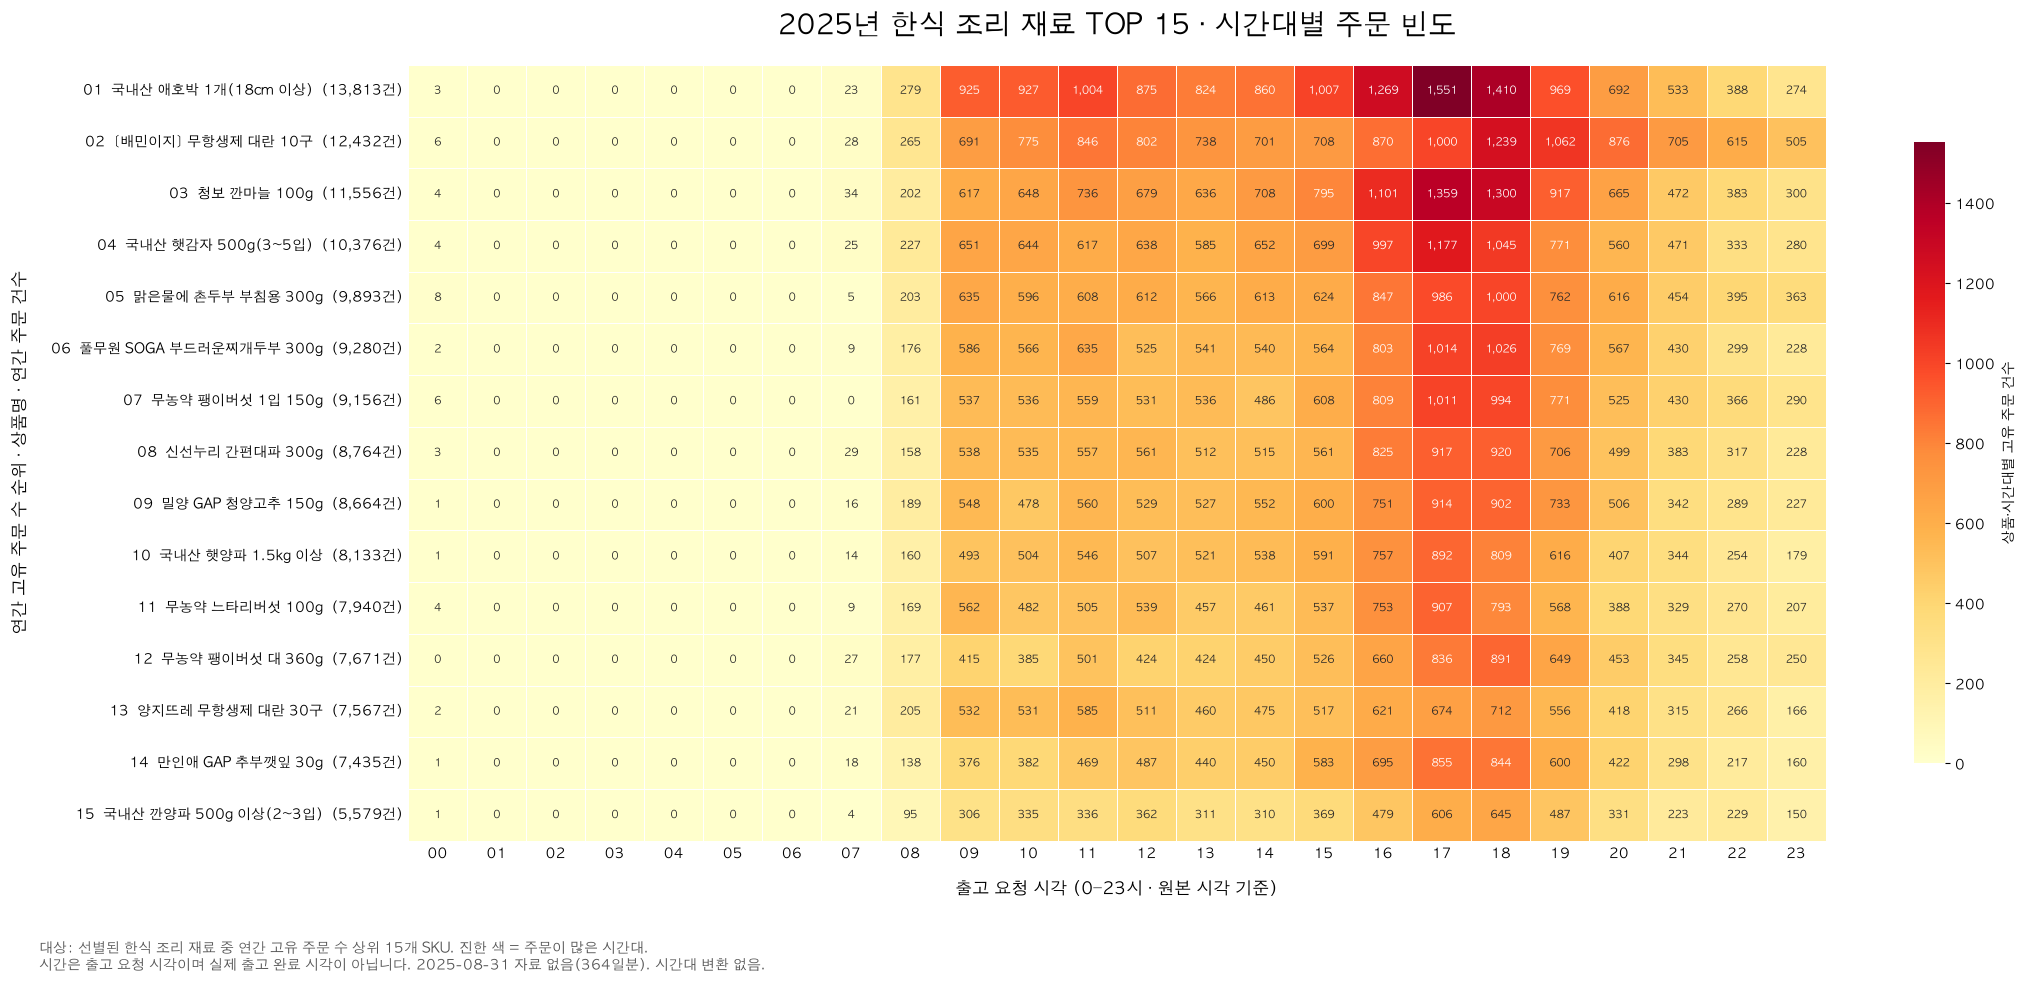

히트맵 이미지: /Users/hoyeonjang/MyProjects/hit-stocks-analysis/reports/hansik_2025/hansik_top15_hourly_heatmap.png


,annual_rank,sku_code,sku_name,annual_order_count
0,1,A20002170,국내산 애호박 1개(18cm 이상),13813
1,2,A20000594,[배민이지] 무항생제 대란 10구,12432
2,3,A20000183,청보 깐마늘 100g,11556
3,4,A20003366,국내산 햇감자 500g(3~5입),10376
4,5,A20000255,맑은물에 촌두부 부침용 300g,9893
5,6,A21003598,풀무원 SOGA 부드러운찌개두부 300g,9280
6,7,A20004316,무농약 팽이버섯 1입 150g,9156
7,8,A20000756,신선누리 간편대파 300g,8764
8,9,A20002338,밀양 GAP 청양고추 150g,8664
9,10,A20002608,국내산 햇양파 1.5kg 이상,8133


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager
from openpyxl.drawing.image import Image as ExcelImage
from openpyxl.formatting.rule import ColorScaleRule
from openpyxl.utils import get_column_letter

HEATMAP_TOP_N = 15
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font in ("AppleGothic", "Malgun Gothic", "NanumGothic"):
    if font in available_fonts:
        plt.rcParams["font.family"] = font
        break
plt.rcParams["axes.unicode_minus"] = False

top_products = products.sort_values(
    ["annual_order_count", "annual_picked_quantity", "sku_code"],
    ascending=[False, False, True],
).head(HEATMAP_TOP_N).reset_index(drop=True)
heatmap_counts = (
    hourly.pivot(index="sku_code", columns="hour", values="order_count")
    .reindex(index=top_products.sku_code, columns=range(24)).fillna(0).astype(int)
)
assert heatmap_counts.shape == (HEATMAP_TOP_N, 24)
assert heatmap_counts.index.is_unique
labels = [
    f"{i + 1:02d}  {row.sku_name}  ({row.annual_order_count:,}건)"
    for i, row in enumerate(top_products.itertuples())
]
fig, ax = plt.subplots(figsize=(22, 10))
sns.heatmap(
    heatmap_counts, ax=ax, cmap="YlOrRd", vmin=0,
    annot=True, fmt=",d", annot_kws={"fontsize": 8},
    linewidths=0.5, linecolor="white",
    xticklabels=[f"{hour:02d}" for hour in range(24)], yticklabels=labels,
    cbar_kws={"label": "상품·시간대별 고유 주문 건수", "shrink": 0.8},
)
ax.set_title("2025년 한식 조리 재료 TOP 15 · 시간대별 주문 빈도", fontsize=20, pad=22)
ax.set_xlabel("출고 요청 시각 (0–23시 · 원본 시각 기준)", fontsize=12, labelpad=12)
ax.set_ylabel("연간 고유 주문 수 순위 · 상품명 · 연간 주문 건수", fontsize=12, labelpad=15)
ax.tick_params(axis="y", labelrotation=0, labelsize=10, length=0)
ax.tick_params(axis="x", labelrotation=0, labelsize=10, length=0)
fig.text(0.02, 0.025,
    "대상: 선별된 한식 조리 재료 중 연간 고유 주문 수 상위 15개 SKU. "
    "진한 색 = 주문이 많은 시간대.\n"
    "시간은 출고 요청 시각이며 실제 출고 완료 시각이 아닙니다. "
    "2025-08-31 자료 없음(364일분). 시간대 변환 없음.",
    fontsize=10, color="#555555")
fig.tight_layout(rect=(0, 0.08, 1, 1))
image_path = REPORT / "hansik_top15_hourly_heatmap.png"
fig.savefig(image_path, dpi=180, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

# 그래프와 동일한 순서의 15 × 24 수치 표를 함께 저장합니다.
heatmap_table = top_products[["sku_code", "sku_name", "annual_order_count"]].copy()
heatmap_table.insert(0, "annual_rank", range(1, len(top_products) + 1))
for hour in range(24):
    heatmap_table[f"{hour:02d}시"] = heatmap_counts[hour].to_numpy()
heatmap_table.to_csv(REPORT / "hansik_top15_hourly_heatmap.csv", index=False, encoding="utf-8-sig")

with pd.ExcelWriter(REPORT / "hansik_ingredients_2025.xlsx",
                    engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
    heatmap_table.to_excel(writer, sheet_name="TOP15_히트맵", index=False, startrow=3)
    sheet = writer.sheets["TOP15_히트맵"]
    sheet["A1"] = "2025년 한식 조리 재료 · 연간 주문 수 TOP 15의 시간대별 고유 주문 건수"
    sheet["A2"] = "출고 요청 시각 기준 / 2025-08-31 자료 없음 / 연간 주문 수와 시간별 합은 다를 수 있음"
    sheet.freeze_panes = "E5"
    sheet.column_dimensions["A"].width = 12
    sheet.column_dimensions["B"].width = 16
    sheet.column_dimensions["C"].width = 46
    sheet.column_dimensions["D"].width = 22
    for col in range(5, 29):
        sheet.column_dimensions[get_column_letter(col)].width = 9
    sheet.conditional_formatting.add(f"E5:AB{4 + len(top_products)}", ColorScaleRule(
        start_type="num", start_value=0, start_color="FFFFCC",
        mid_type="num", mid_value=float(heatmap_counts.to_numpy().max()) / 2, mid_color="FD8D3C",
        end_type="num", end_value=float(heatmap_counts.to_numpy().max()), end_color="800026",
    ))
    excel_image = ExcelImage(image_path)
    excel_image.width, excel_image.height = 1650, excel_image.height * 1650 / excel_image.width
    sheet.add_image(excel_image, "A23")

print("히트맵 이미지:", image_path)
display(heatmap_table[["annual_rank", "sku_code", "sku_name", "annual_order_count"]])

## 5. 출고 행 데이터셋 사용 및 검증

원본 열과 분석용 시각·수량·분류 근거가 함께 저장됩니다.
SKU 조인으로 출고 행이 늘어나지 않았는지, 수량 및 고유 주문 수가 일치하는지 확인합니다.

In [8]:
outbound = pd.read_parquet(DATA / "outbound_ingredients.parquet")
assert len(outbound) == summary["selected_outbound_rows"]
assert outbound.order_id.nunique() == summary["selected_unique_orders"]
assert outbound.picked_quantity.sum() == summary["selected_picked_quantity"]
assert set(outbound.sku_code) <= set(products.sku_code)
assert outbound.status.eq("SHIPPED").all() and outbound.picked_quantity.gt(0).all()
assert outbound.requested_at.dt.year.eq(2025).all()
print(f"검증 통과: {len(products):,}개 상품, {len(outbound):,}행")
display(outbound[["requested_at", "sku_code", "skuName", "picked_quantity",
                  "ingredient_names", "source_ids"]].head())

검증 통과: 870개 상품, 476,671행


,requested_at,sku_code,skuName,picked_quantity,ingredient_names,source_ids
0,2025-01-01 08:42:31,A20001557,새롬 깐대파 200g,1.0,대파·쪽파,K03;K05
1,2025-01-01 08:42:31,A21004101,미정당 방앗간참쌀떡국떡 400g,1.0,떡국떡·떡볶이떡,K06;M01
2,2025-01-01 08:42:32,A20001746,국내산 오이맛고추 200g,2.0,고추,K01;M01
3,2025-01-01 08:42:32,A20003934,친환경 손질 쌈배추 100g,1.0,배추,C01;M01
4,2025-01-01 08:42:32,A21004101,미정당 방앗간참쌀떡국떡 400g,1.0,떡국떡·떡볶이떡,K06;M01


## 6. 추가 검토 목록

`review`와 `not_matched`는 비한식 확정이 아닙니다. 상품 상세 원재료·조리 방법을
추가 확인하면 포함 범위를 넓힐 수 있습니다. 현재 노트북은 이 항목들을 본 데이터에 넣지 않습니다.

In [9]:
display(audit.loc[audit.classification == "review",
    ["sku_code", "sku_name", "annual_order_count", "classification_reason"]].head(20))
print("출고 데이터:", DATA / "outbound_ingredients.parquet")
print("상품 목록:", DATA / "products.csv")
print("Excel 결과:", REPORT / "hansik_ingredients_2025.xlsx")

,sku_code,sku_name,annual_order_count,classification_reason
172,A21002336,프링글스 양파맛 110g,1706,혼합·조리 여부 또는 재료명 이후 상품 형태 확인 필요: 맛 110g
192,A21001490,롯데 돼지바 70ml,1588,혼합·조리 여부 또는 재료명 이후 상품 형태 확인 필요: 바 70ml
202,A21019768,부드러운 오징어 장족 150g,1522,혼합·조리 여부 또는 재료명 이후 상품 형태 확인 필요: 장족 150g
210,A21006795,오리온 오징어땅콩 202g,1480,혼합·조리 여부 또는 재료명 이후 상품 형태 확인 필요: 땅콩 202g
270,A21002040,한양 오징어숏다리 20g,1260,혼합·조리 여부 또는 재료명 이후 상품 형태 확인 필요: 숏다리 20g
540,A21008563,크라운 참쌀 선과 253g,761,혼합·조리 여부 또는 재료명 이후 상품 형태 확인 필요: 선과 253g
624,A21013036,상하농원 고창 황토고구마 스틱 60g,666,혼합·조리 여부 또는 재료명 이후 상품 형태 확인 필요: 스틱 60g
806,S0006778,(26년 1월 1일부터 판매종료) 종가 배추겉절이 1.1kg (용기),547,혼합·조리 여부 또는 재료명 이후 상품 형태 확인 필요: 겉절이 1.1kg (용기)
864,A20002071,친환경 감자 (깍뚝썰기) 200g,523,혼합·조리 여부 또는 재료명 이후 상품 형태 확인 필요: (깍뚝썰기) 200g
892,A21006081,풀무원 식물성 지구식단 두부면 넓은면 100g,507,혼합·조리 여부 또는 재료명 이후 상품 형태 확인 필요: 면 넓은면 100g


출고 데이터: /Users/hoyeonjang/MyProjects/hit-stocks-analysis/data/hansik_2025/outbound_ingredients.parquet
상품 목록: /Users/hoyeonjang/MyProjects/hit-stocks-analysis/data/hansik_2025/products.csv
Excel 결과: /Users/hoyeonjang/MyProjects/hit-stocks-analysis/reports/hansik_2025/hansik_ingredients_2025.xlsx
